In [1]:
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import polars.selectors as cs
import math
import seaborn as sns

In [2]:
df = pl.read_csv('../data/ofiq_glint_200.csv', separator=';').drop(['Filename','assessment_time_in_ms', ''])
df.head(5)

UnifiedQualityScore.native,BackgroundUniformity.native,IlluminationUniformity.native,LuminanceMean.native,LuminanceVariance.native,UnderExposurePrevention.native,OverExposurePrevention.native,DynamicRange.native,Sharpness.native,NoCompressionArtifacts.native,NaturalColour.native,SingleFacePresent.native,EyesOpen.native,MouthClosed.native,EyesVisible.native,MouthOcclusionPrevention.native,FaceOcclusionPrevention.native,InterEyeDistance.native,HeadSize.native,LeftwardCropOfFace.native,RightwardCropOfFace.native,MarginAboveTheFace.native,MarginBelowTheFace.native,HeadPoseYawFrontal.native,HeadPosePitchFrontal.native,HeadPoseRollFrontal.native,ExpressionNeutrality.native,NoHeadCoverings.native,UnifiedQualityScore.scalar,BackgroundUniformity.scalar,IlluminationUniformity.scalar,LuminanceMean.scalar,LuminanceVariance.scalar,UnderExposurePrevention.scalar,OverExposurePrevention.scalar,DynamicRange.scalar,Sharpness.scalar,NoCompressionArtifacts.scalar,NaturalColour.scalar,SingleFacePresent.scalar,EyesOpen.scalar,MouthClosed.scalar,EyesVisible.scalar,MouthOcclusionPrevention.scalar,FaceOcclusionPrevention.scalar,InterEyeDistance.scalar,HeadSize.scalar,LeftwardCropOfFace.scalar,RightwardCropOfFace.scalar,MarginAboveTheFace.scalar,MarginBelowTheFace.scalar,HeadPoseYawFrontal.scalar,HeadPosePitchFrontal.scalar,HeadPoseRollFrontal.scalar,ExpressionNeutrality.scalar,NoHeadCoverings.scalar
f64,f64,f64,f64,f64,f64,f64,f64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64
26.044502,10.15281,0.095156,0.266998,0.019148,0.080445,0.0,6.880334,42,0.955792,0.0,0.0,0.0806,0.0,0.0,0.0,0.013876,35.341612,0.531269,2.084863,2.113423,0.898305,1.0,-7.8041,12.923698,1.055759,-6007.103027,0.162564,76,95,49,79,99,100,100,86,99,100,100,100,100,97,100,100,99,15,33,100,100,1,0,98,95,100,45,35
21.445459,2.248353,0.635918,0.272078,0.006677,0.014846,0.0,6.319742,17,0.953826,5.598051,0.0,0.053024,0.017241,0.0,0.0,0.015189,37.418484,0.517876,1.988414,2.015285,0.948135,0.982613,5.96935,-7.072129,-2.157424,2294.296387,0.0,35,99,87,81,78,100,100,79,92,100,73,100,96,95,100,100,98,16,41,100,100,1,0,99,98,100,81,100
24.721661,125.41423,0.256198,0.146763,0.006718,0.307565,0.0,6.256595,43,0.960335,0.0,0.0,0.08117,0.0,0.0,0.0,0.037744,36.390601,0.553589,2.085714,2.114286,0.854728,0.951489,15.890482,14.129109,-3.418135,7065.283691,0.154974,66,46,66,26,78,100,100,78,99,100,100,100,100,97,100,100,96,16,22,100,100,0,0,93,94,100,92,37
20.054932,35.655131,0.313776,0.283655,0.025906,0.036248,0.0,6.871592,27,0.957361,0.0,0.0,0.090348,0.122863,0.002524,0.0,0.242008,34.771191,0.585894,2.466667,2.266667,0.822918,0.883875,-30.369466,-6.394851,-5.918356,-13468.097656,0.0,24,83,71,84,94,100,100,86,96,100,100,100,100,78,100,100,76,15,12,100,100,0,0,74,99,99,16,100
22.919014,54.321746,0.208984,0.188464,0.037218,0.48208,0.0,6.649698,30,0.958021,5.625234,0.0,0.080401,0.0,0.0,0.0,0.015584,33.200985,0.540197,2.180817,2.211106,0.883211,0.983197,6.064997,17.862224,-0.072234,3033.088867,0.161888,49,74,63,44,83,100,100,83,97,100,73,100,100,97,100,100,98,14,28,100,100,1,0,99,91,100,83,35


In [3]:
df.select(pl.col(pl.Float32,pl.Float64).is_nan().sum())

UnifiedQualityScore.native,BackgroundUniformity.native,IlluminationUniformity.native,LuminanceMean.native,LuminanceVariance.native,UnderExposurePrevention.native,OverExposurePrevention.native,DynamicRange.native,NoCompressionArtifacts.native,NaturalColour.native,SingleFacePresent.native,EyesOpen.native,MouthClosed.native,EyesVisible.native,MouthOcclusionPrevention.native,FaceOcclusionPrevention.native,InterEyeDistance.native,HeadSize.native,LeftwardCropOfFace.native,RightwardCropOfFace.native,MarginAboveTheFace.native,MarginBelowTheFace.native,HeadPoseYawFrontal.native,HeadPosePitchFrontal.native,HeadPoseRollFrontal.native,ExpressionNeutrality.native,NoHeadCoverings.native
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,2,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [4]:
# Togliere le entry con NaN
df = df.filter(
    ~pl.any_horizontal(pl.col(pl.Float32, pl.Float64).is_nan())\
)

In [5]:
native = df.select(cs.ends_with('.native'))
scalar = df.select(cs.ends_with('.scalar'))
print(scalar.shape)
print(native.shape)
scalar.columns

(198, 28)
(198, 28)


['UnifiedQualityScore.scalar',
 'BackgroundUniformity.scalar',
 'IlluminationUniformity.scalar',
 'LuminanceMean.scalar',
 'LuminanceVariance.scalar',
 'UnderExposurePrevention.scalar',
 'OverExposurePrevention.scalar',
 'DynamicRange.scalar',
 'Sharpness.scalar',
 'NoCompressionArtifacts.scalar',
 'NaturalColour.scalar',
 'SingleFacePresent.scalar',
 'EyesOpen.scalar',
 'MouthClosed.scalar',
 'EyesVisible.scalar',
 'MouthOcclusionPrevention.scalar',
 'FaceOcclusionPrevention.scalar',
 'InterEyeDistance.scalar',
 'HeadSize.scalar',
 'LeftwardCropOfFace.scalar',
 'RightwardCropOfFace.scalar',
 'MarginAboveTheFace.scalar',
 'MarginBelowTheFace.scalar',
 'HeadPoseYawFrontal.scalar',
 'HeadPosePitchFrontal.scalar',
 'HeadPoseRollFrontal.scalar',
 'ExpressionNeutrality.scalar',
 'NoHeadCoverings.scalar']

#### Data distribution

In [6]:
def create_histograms(df):
    col = 4
    row = math.ceil(df.shape[1]/ col)
    fig, ax = plt.subplots(row, col, figsize=(20, col * row))
    ax = np.array(ax).flatten()
    for i, col in enumerate(df.columns):
        values = df[col].drop_nulls().to_numpy()
        values = values[~np.isnan(values)] 
        ax[i].hist(values, bins='auto')
        ax[i].set_title(col)

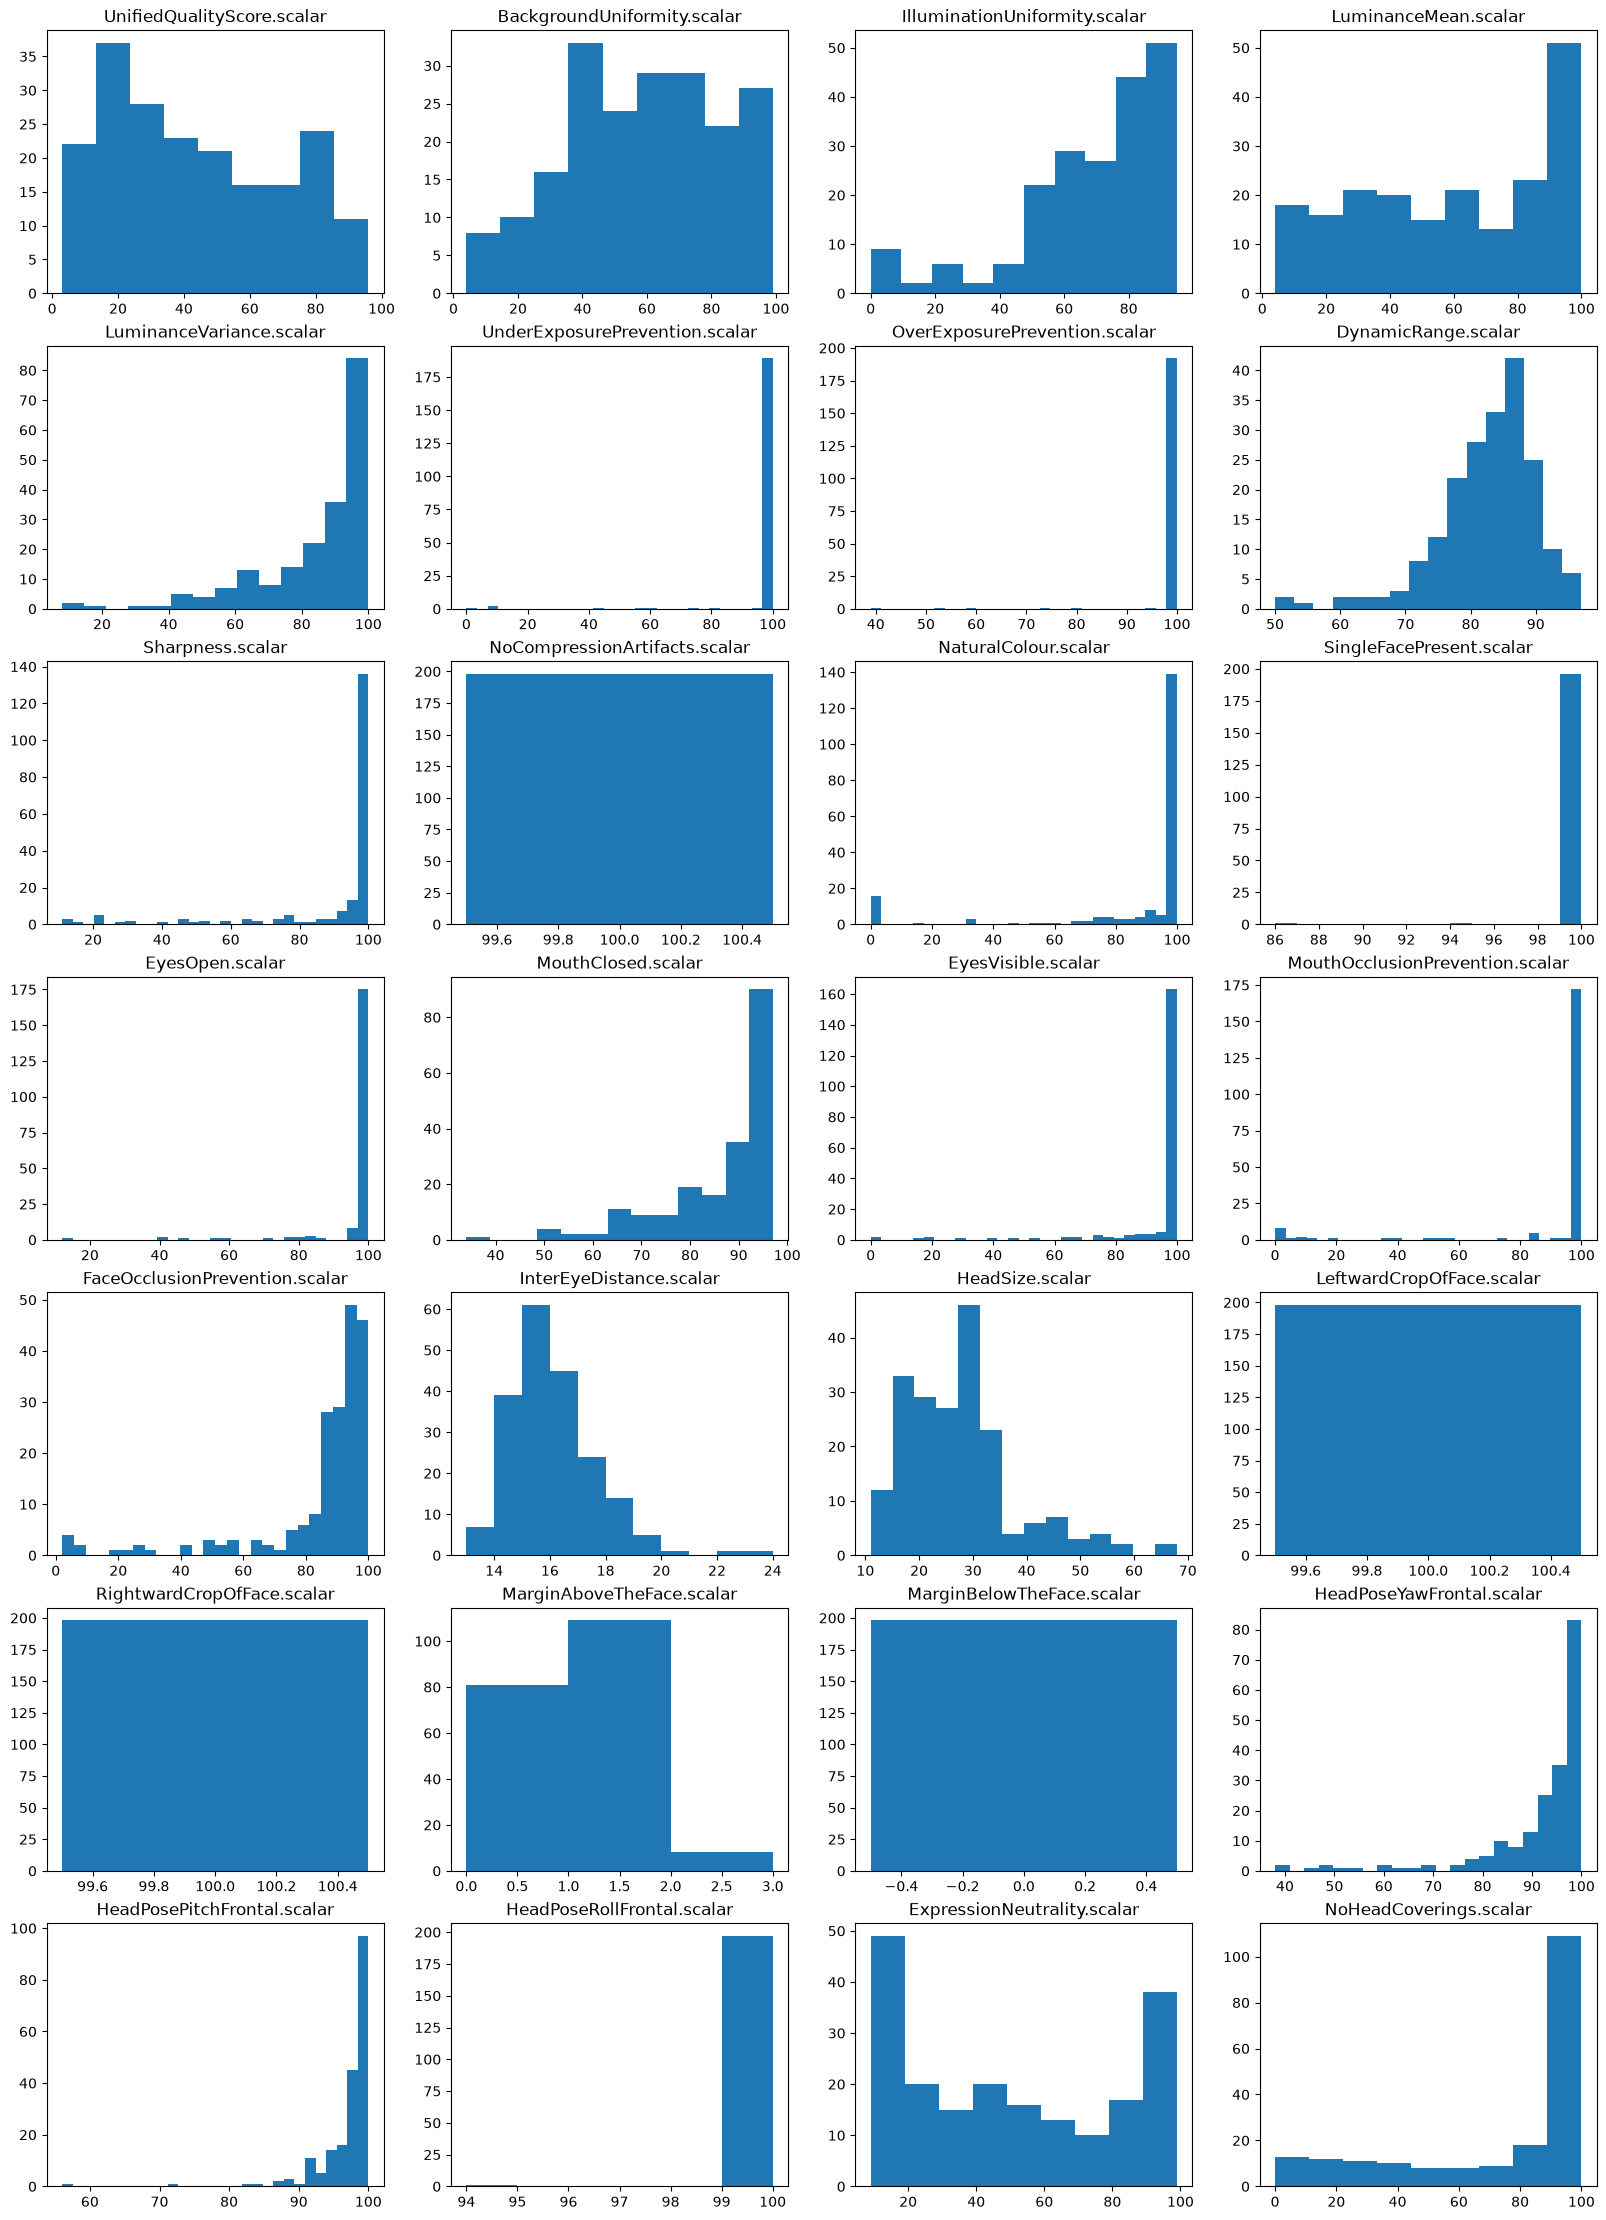

In [7]:
create_histograms(scalar)

There are 4 columns that cannot be explained by the histogram in the scalar dataframe. These columns are: Left/RightWardCropOfFace, MarginBelowtheFace and NoCompressionartifact.

Most of these histograms show repetitive pattern, peak at the max value with a skew on the left, with only few exception with peak at the minimum value but often followed with another peak with less height.

This shows that a dataset with 200 images can't put a good distribution for each one of the features, it can be solved by adding more inputs or without using scalar values and go straight to the .native values.

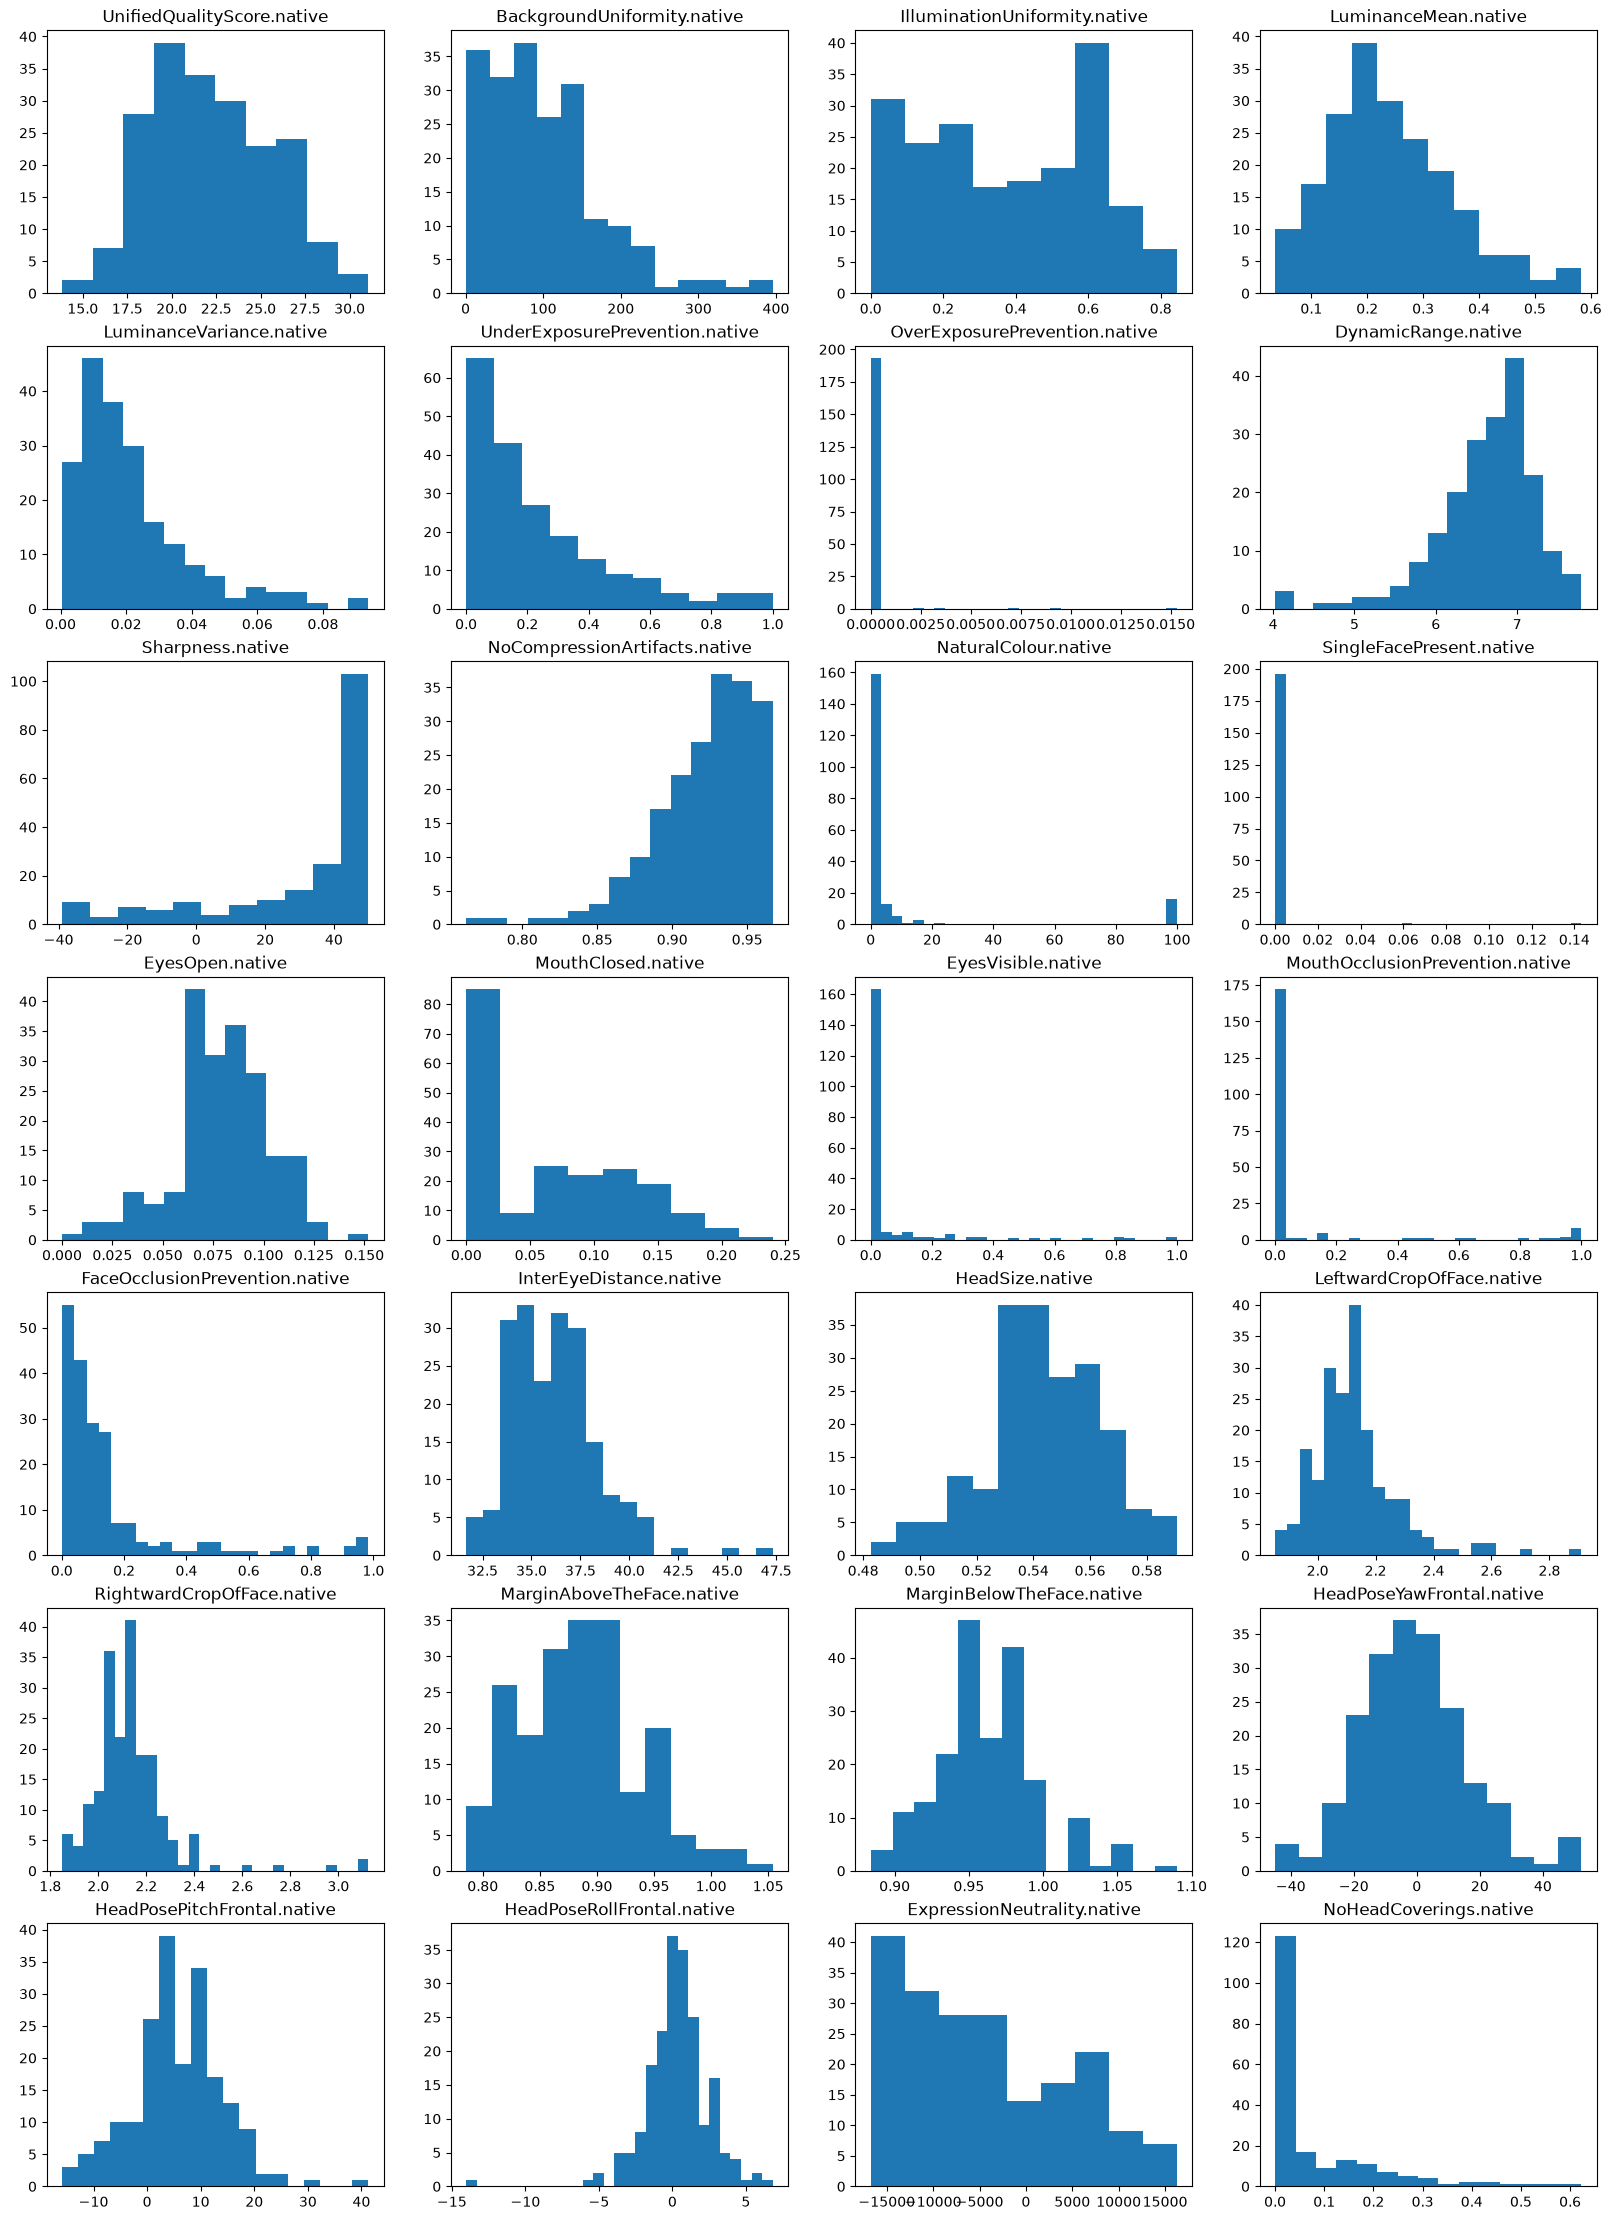

In [8]:
create_histograms(native)

With the .native DataFrame we cen see different type if distribution in comparison of the .scalar dataframe. 
9 out of the 28 columns shows peak near the min value of the feature with a right skew, but rather it is optimal for the other features that have much stronger distribution of datas.

We will continue the data exploration with the .native.

#### Mean and Variabilty of the data

In [9]:
df_describe = native.describe()
mean = df_describe.filter(pl.col('statistic') == 'mean')
median = df_describe.filter(pl.col('statistic') == '50%')

In [10]:
df_describe

statistic,UnifiedQualityScore.native,BackgroundUniformity.native,IlluminationUniformity.native,LuminanceMean.native,LuminanceVariance.native,UnderExposurePrevention.native,OverExposurePrevention.native,DynamicRange.native,Sharpness.native,NoCompressionArtifacts.native,NaturalColour.native,SingleFacePresent.native,EyesOpen.native,MouthClosed.native,EyesVisible.native,MouthOcclusionPrevention.native,FaceOcclusionPrevention.native,InterEyeDistance.native,HeadSize.native,LeftwardCropOfFace.native,RightwardCropOfFace.native,MarginAboveTheFace.native,MarginBelowTheFace.native,HeadPoseYawFrontal.native,HeadPosePitchFrontal.native,HeadPoseRollFrontal.native,ExpressionNeutrality.native,NoHeadCoverings.native
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",198.0,198.0,198.0,198.0,198.0,198.0,198.0,198.0,198.0,198.0,198.0,198.0,198.0,198.0,198.0,198.0,198.0,198.0,198.0,198.0,198.0,198.0,198.0,198.0,198.0,198.0,198.0,198.0
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",22.132393,100.853929,0.376801,0.242983,0.021692,0.234839,0.000194,6.621006,30.19697,0.921219,9.241063,0.001031,0.079281,0.066433,0.057943,0.082175,0.151957,36.187213,0.544384,2.127295,2.134636,0.884376,0.962779,-0.879264,5.859212,0.330204,-4378.339381,0.07679
"""std""",3.3548,74.519528,0.239221,0.112782,0.017483,0.225891,0.001397,0.622569,24.585427,0.034425,27.161944,0.011042,0.023697,0.059494,0.171445,0.249235,0.208173,2.237648,0.020506,0.147421,0.171955,0.051718,0.034727,17.088732,8.351514,2.208886,8572.953699,0.119804
"""min""",13.8334,1.046197,0.0,0.035087,0.000445,0.000885,0.0,4.024136,-39.0,0.762684,0.0,0.0,0.0,0.0,0.0,0.0,0.000756,31.674328,0.482659,1.853107,1.848716,0.785628,0.883875,-44.959758,-15.872056,-14.011323,-16726.265625,0.0
"""25%""",19.638424,48.601153,0.159209,0.164604,0.009339,0.063871,0.0,6.316064,21.0,0.904091,0.0,0.0,0.065834,0.016103,0.0,0.0,0.036077,34.742742,0.531925,2.052391,2.052391,0.843647,0.937386,-12.554953,1.397369,-0.803041,-12380.164062,0.0
"""50%""",21.793493,89.283887,0.38,0.222291,0.017481,0.158006,0.0,6.760078,42.0,0.928189,0.0,0.0,0.080808,0.065574,0.0,0.0,0.081976,36.02369,0.544661,2.113423,2.113993,0.882843,0.964855,-1.428345,5.16239,0.343113,-5823.037598,0.016543
"""75%""",24.721661,140.715814,0.595102,0.30936,0.028896,0.346604,0.0,7.017951,47.0,0.946543,1.863255,0.0,0.097322,0.112889,0.002994,0.0,0.151839,37.418484,0.558678,2.180817,2.181818,0.915523,0.983051,9.988685,10.554413,1.314606,2600.823242,0.122577
"""max""",31.052729,395.768615,0.844907,0.583102,0.093836,1.0,0.015318,7.789009,50.0,0.967013,100.0,0.143302,0.15204,0.240034,1.0,1.0,0.983801,47.320098,0.590654,2.910294,3.125,1.05393,1.090189,52.218863,41.29202,6.823864,16291.250977,0.622972


In [11]:
mean

statistic,UnifiedQualityScore.native,BackgroundUniformity.native,IlluminationUniformity.native,LuminanceMean.native,LuminanceVariance.native,UnderExposurePrevention.native,OverExposurePrevention.native,DynamicRange.native,Sharpness.native,NoCompressionArtifacts.native,NaturalColour.native,SingleFacePresent.native,EyesOpen.native,MouthClosed.native,EyesVisible.native,MouthOcclusionPrevention.native,FaceOcclusionPrevention.native,InterEyeDistance.native,HeadSize.native,LeftwardCropOfFace.native,RightwardCropOfFace.native,MarginAboveTheFace.native,MarginBelowTheFace.native,HeadPoseYawFrontal.native,HeadPosePitchFrontal.native,HeadPoseRollFrontal.native,ExpressionNeutrality.native,NoHeadCoverings.native
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""mean""",22.132393,100.853929,0.376801,0.242983,0.021692,0.234839,0.000194,6.621006,30.19697,0.921219,9.241063,0.001031,0.079281,0.066433,0.057943,0.082175,0.151957,36.187213,0.544384,2.127295,2.134636,0.884376,0.962779,-0.879264,5.859212,0.330204,-4378.339381,0.07679


In [12]:
median

statistic,UnifiedQualityScore.native,BackgroundUniformity.native,IlluminationUniformity.native,LuminanceMean.native,LuminanceVariance.native,UnderExposurePrevention.native,OverExposurePrevention.native,DynamicRange.native,Sharpness.native,NoCompressionArtifacts.native,NaturalColour.native,SingleFacePresent.native,EyesOpen.native,MouthClosed.native,EyesVisible.native,MouthOcclusionPrevention.native,FaceOcclusionPrevention.native,InterEyeDistance.native,HeadSize.native,LeftwardCropOfFace.native,RightwardCropOfFace.native,MarginAboveTheFace.native,MarginBelowTheFace.native,HeadPoseYawFrontal.native,HeadPosePitchFrontal.native,HeadPoseRollFrontal.native,ExpressionNeutrality.native,NoHeadCoverings.native
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""50%""",21.793493,89.283887,0.38,0.222291,0.017481,0.158006,0.0,6.760078,42.0,0.928189,0.0,0.0,0.080808,0.065574,0.0,0.0,0.081976,36.02369,0.544661,2.113423,2.113993,0.882843,0.964855,-1.428345,5.16239,0.343113,-5823.037598,0.016543


In [13]:
for c1, c2 in zip(mean.columns, median.columns):
    print(f"Column {c1}")
    print(f"Mean: {mean[c1].to_numpy().item()}")
    print(f"Median: {median[c1].to_numpy().item()}")
    print("==============")

Column statistic
Mean: mean
Median: 50%
Column UnifiedQualityScore.native
Mean: 22.132392545454547
Median: 21.793493
Column BackgroundUniformity.native
Mean: 100.85392926767675
Median: 89.283887
Column IlluminationUniformity.native
Mean: 0.3768009494949494
Median: 0.38
Column LuminanceMean.native
Mean: 0.24298333333333333
Median: 0.222291
Column LuminanceVariance.native
Mean: 0.021691919191919193
Median: 0.017481
Column UnderExposurePrevention.native
Mean: 0.23483908080808083
Median: 0.158006
Column OverExposurePrevention.native
Mean: 0.00019398484848484848
Median: 0.0
Column DynamicRange.native
Mean: 6.6210063989898975
Median: 6.760078
Column Sharpness.native
Mean: 30.196969696969695
Median: 42.0
Column NoCompressionArtifacts.native
Mean: 0.921218595959596
Median: 0.928189
Column NaturalColour.native
Mean: 9.24106296969697
Median: 0.0
Column SingleFacePresent.native
Mean: 0.0010306363636363638
Median: 0.0
Column EyesOpen.native
Mean: 0.07928125252525252
Median: 0.080808
Column MouthCl

In [14]:
distance = df_describe.select(
    cs.numeric().filter(pl.col("statistic") == "max").first()
    - cs.numeric().filter(pl.col("statistic") == "min").first()
)

for col in distance.columns:
    print(col)
    print(f"Distanza: {distance[col].to_numpy().item()}")
    print("============")

UnifiedQualityScore.native
Distanza: 17.219329000000002
BackgroundUniformity.native
Distanza: 394.722418
IlluminationUniformity.native
Distanza: 0.844907
LuminanceMean.native
Distanza: 0.548015
LuminanceVariance.native
Distanza: 0.093391
UnderExposurePrevention.native
Distanza: 0.999115
OverExposurePrevention.native
Distanza: 0.015318
DynamicRange.native
Distanza: 3.7648729999999997
Sharpness.native
Distanza: 89.0
NoCompressionArtifacts.native
Distanza: 0.20432899999999998
NaturalColour.native
Distanza: 100.0
SingleFacePresent.native
Distanza: 0.143302
EyesOpen.native
Distanza: 0.15204
MouthClosed.native
Distanza: 0.240034
EyesVisible.native
Distanza: 1.0
MouthOcclusionPrevention.native
Distanza: 1.0
FaceOcclusionPrevention.native
Distanza: 0.9830450000000001
InterEyeDistance.native
Distanza: 15.645770000000002
HeadSize.native
Distanza: 0.10799500000000001
LeftwardCropOfFace.native
Distanza: 1.0571869999999999
RightwardCropOfFace.native
Distanza: 1.276284
MarginAboveTheFace.native
Dist

In [15]:
std = df_describe.filter(pl.col('statistic') == 'std')

for col in std.columns:
    print(col)
    print(f"Varianza: {std[col].to_numpy().item()}")
    print("========================")

statistic
Varianza: std
UnifiedQualityScore.native
Varianza: 3.3548003285268693
BackgroundUniformity.native
Varianza: 74.51952757612418
IlluminationUniformity.native
Varianza: 0.23922092972020753
LuminanceMean.native
Varianza: 0.11278245941261149
LuminanceVariance.native
Varianza: 0.01748314329302956
UnderExposurePrevention.native
Varianza: 0.22589128031097505
OverExposurePrevention.native
Varianza: 0.001396936323223011
DynamicRange.native
Varianza: 0.6225686029873998
Sharpness.native
Varianza: 24.58542738090219
NoCompressionArtifacts.native
Varianza: 0.03442533573880327
NaturalColour.native
Varianza: 27.161944465058568
SingleFacePresent.native
Varianza: 0.011041547990636728
EyesOpen.native
Varianza: 0.023697326043695028
MouthClosed.native
Varianza: 0.05949423296443753
EyesVisible.native
Varianza: 0.17144471588057145
MouthOcclusionPrevention.native
Varianza: 0.2492354853223551
FaceOcclusionPrevention.native
Varianza: 0.2081728955223705
InterEyeDistance.native
Varianza: 2.23764771528667

Grandi range tra massimo e minimo:
- Sharpness.native --> Distanza: 89.0
- BackgroundUniformity.native --> Distanza: 394.722418
- ExpressionNeutrality.native --> Distanza: 33017.516602

Grande varianza fra i dati:
- ExpressionNeutrality.native --> Varianza: 8572.953698773426
- BackgroundUniformity.native --> Varianza: 74.51952757612418
- NaturalColour.native --> Varianza: 27.161944465058568

#### Eventuali correlazioni

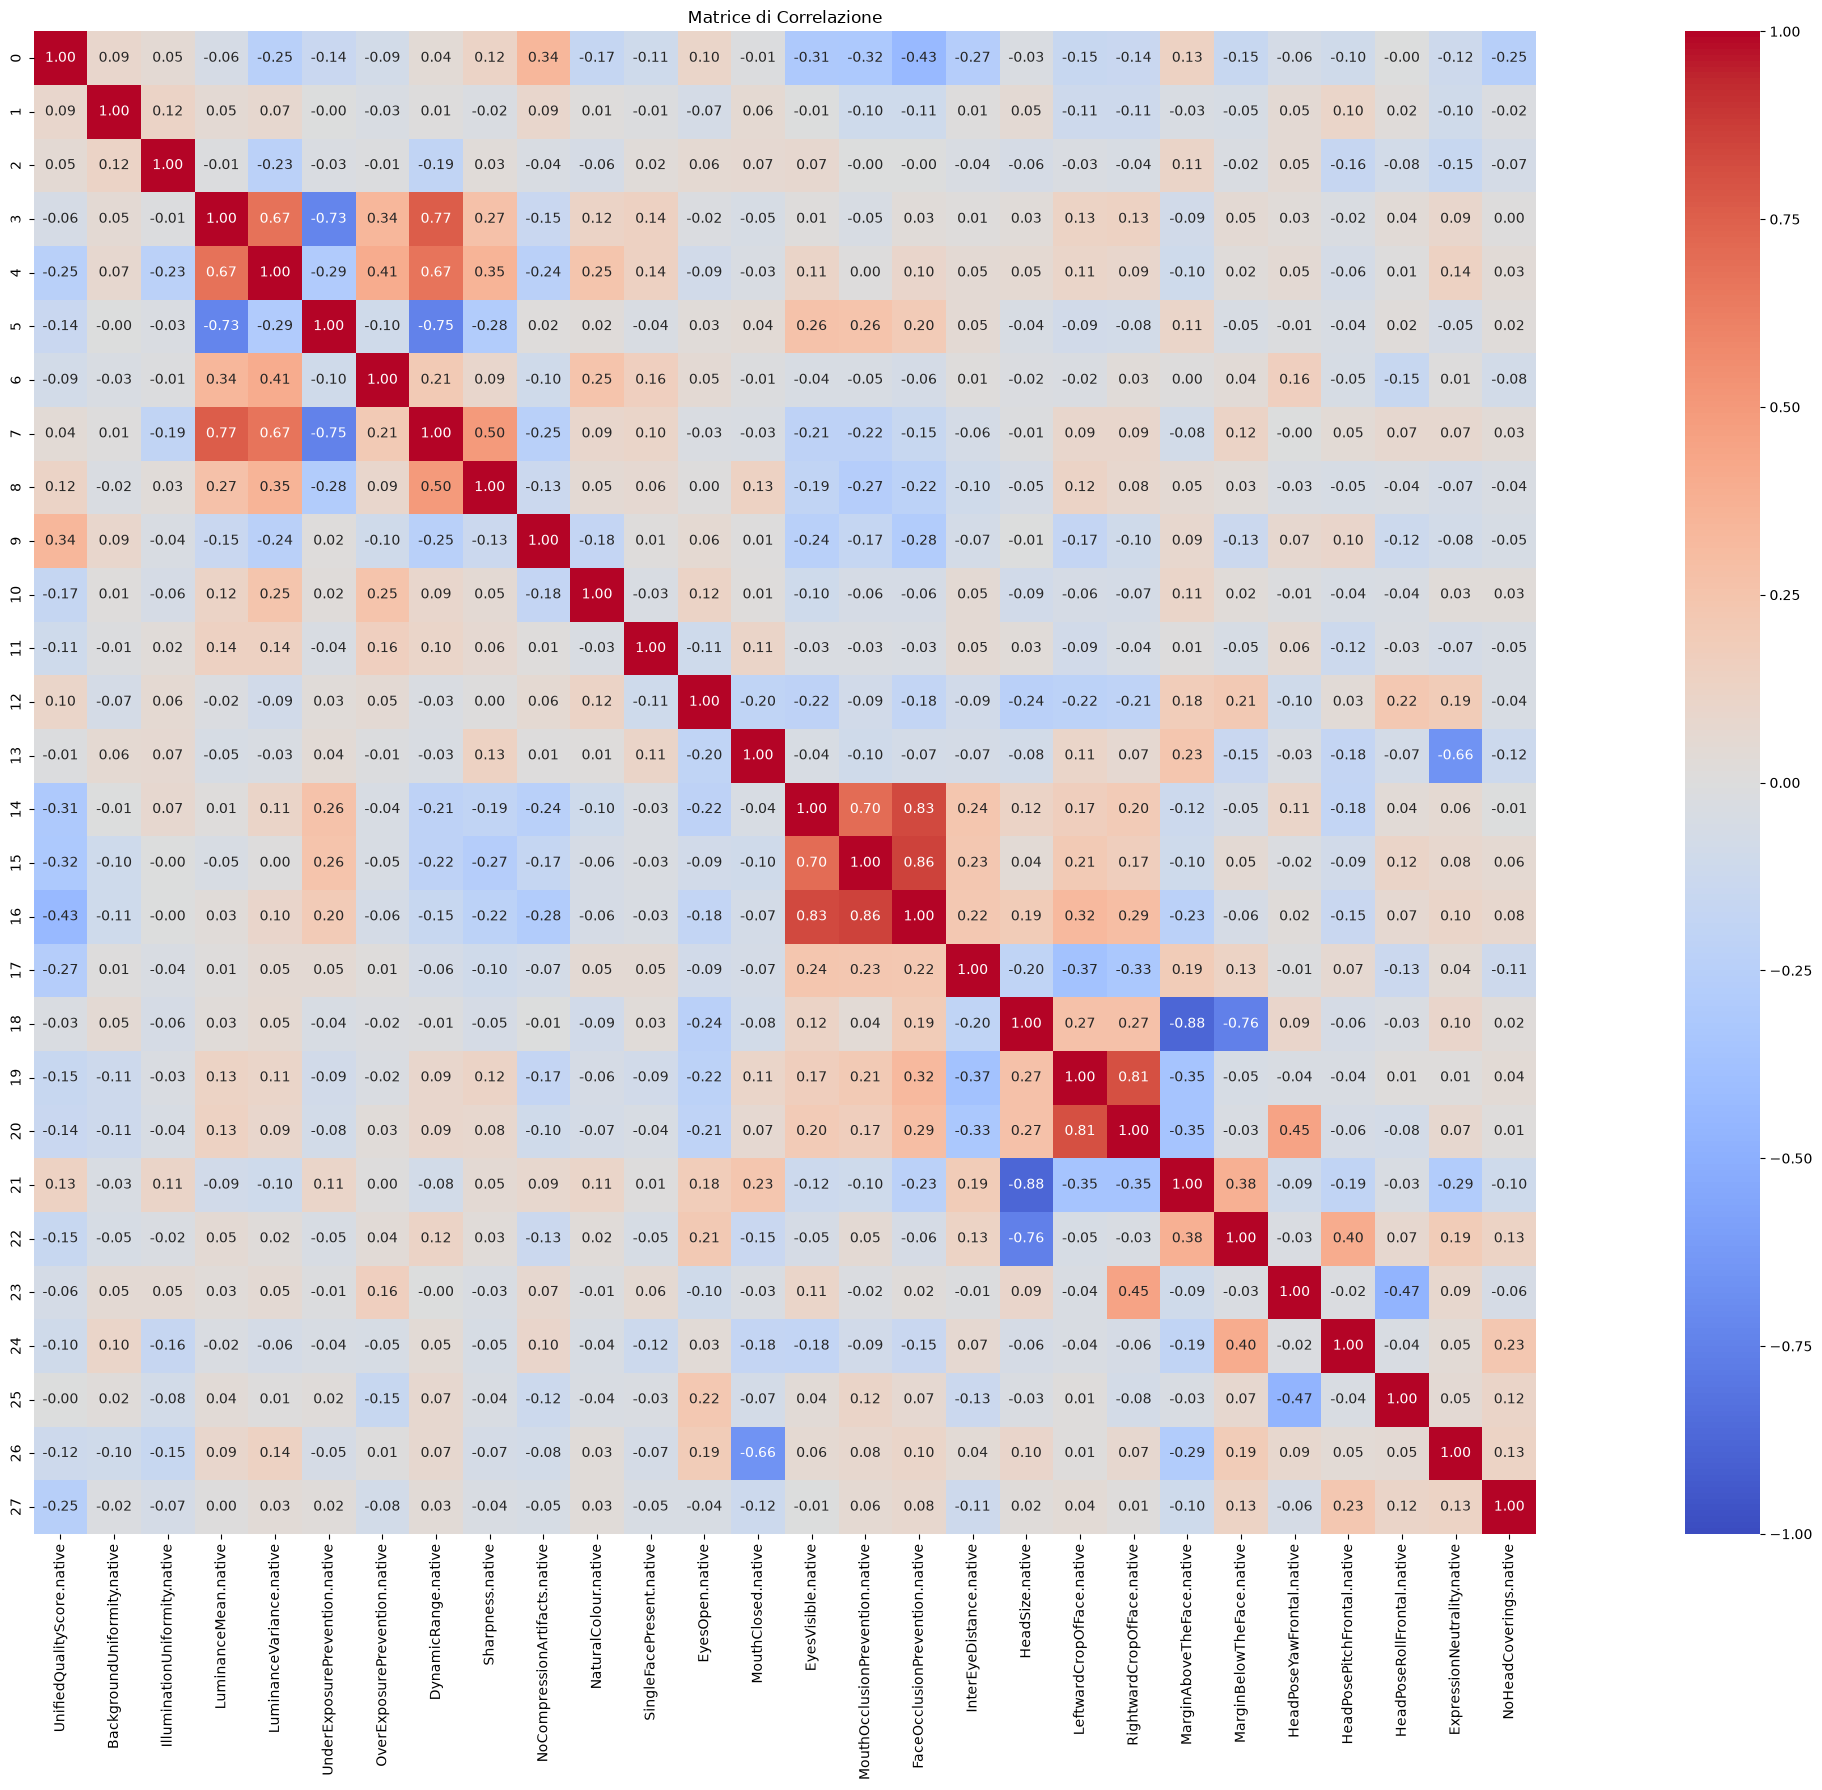

In [18]:
corr_df = native.select(cs.numeric()).corr()

plt.figure(figsize=(30, 18))

sns.heatmap(
    corr_df.to_pandas(), 
    annot=True,          
    fmt=".2f",         
    cmap="coolwarm",     
    vmin=-1, vmax=1,     
    square=True
)

plt.title("Matrice di Correlazione")
plt.tight_layout()
plt.show()